This task, explores the underlying relationships between different crime rates across the United States and urban density in 1973. PCA is used to reduce the dimensionality of the US Arrests dataset, identifying the principal components that capture the most significant variation in the crime rates. The US Arrests dataset contains information about arrests per 100,000 residents for assault, murder, and rape in each of the 50 US states. The percentage of people living in urban areas is also provided.

In [55]:
# Load libraries
import pandas as pd
import numpy as np

# Visualisation libraries
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.impute import KNNImputer  # You will need the scikit-learn version >= 0.22
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, silhouette_score


from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans
from sklearn import metrics

## Exploring the data

We need to clean up the data for analysis and for calculations 

In [56]:
# Load the dataset and use the country column as index.
df = pd.read_csv('UsArrests.csv', index_col='City')
df.head()

,Murder,Assault,UrbanPop,Rape
City,,,,
Alabama,13.200000,236,58,21.200000
Alaska,10.000000,263,48,44.500000
Arizona,8.100000,294,80,31.000000
Arkansas,8.800000,190,50,19.500000
California,9.000000,276,91,40.600000


In [57]:
# Printing the shape of the dataset
print('Number of Cities: {} Number of features: {}'.format(df.shape[0], df.shape[1]))

Number of Cities: 50 Number of features: 4


#### 3. Identify any missing values and see which features are affected
#### Explore the data and motivate any preprocessing steps you take.

In [58]:
# Count missing values
missing = df.isnull().sum()
relevant_missing = pd.DataFrame(missing, columns=["missing"])
relevant_missing

,missing
Murder,0
Assault,0
UrbanPop,0
Rape,0


### Explore the features and statistical properties of the dataset

In [59]:
# To set the decimal precision:
pd.set_option('display.float_format', lambda x: '%2f' % x)

# The describe() function gives us insight into the statistical properties of the columns
stats = df.describe()
selected_stats = stats.loc[["mean","std","min","max"]].transpose() # select relevant colums
selected_stats


,mean,std,min,max
Murder,7.788000,4.355510,0.800000,17.400000
Assault,170.760000,83.337661,45.000000,337.000000
UrbanPop,65.540000,14.474763,32.000000,91.000000
Rape,21.232000,9.366385,7.300000,46.000000


#### 4. Perform a correlation analysis and interpret the output

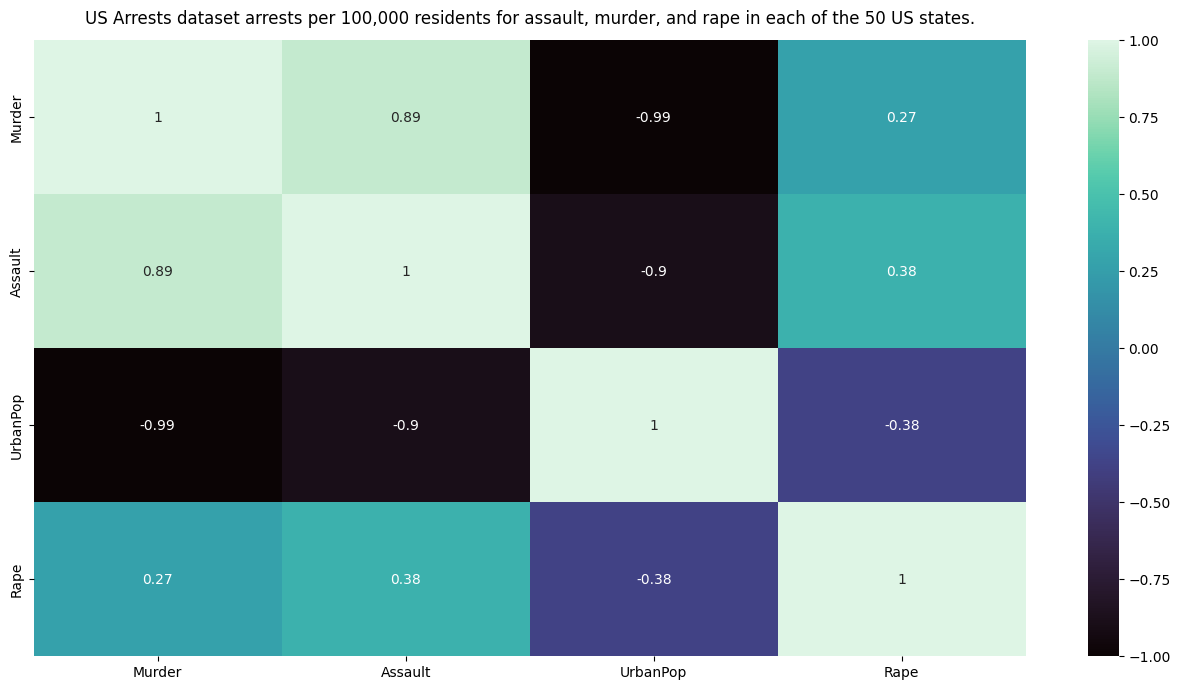

In [60]:
# Create a correlation map of features to explore the relationship between features
# Hint: Explore seaborn heatmap
arrests = df.index
corr_df = df.corr()
labels = corr_df.columns

correlations = corr_df.corr()
plt.figure(figsize=(16, 8))
sns.heatmap(corr_df.corr(), vmin = -1, annot = True, cmap = 'mako')
plt.title('US Arrests dataset arrests per 100,000 residents for assault, murder, and rape in each of the 50 US states.', fontdict={'fontsize':12}, pad=12);

#### Unstandardized data

In [61]:
# Run again if it does not converge the first time
np.set_printoptions(precision=3)

X = df.iloc[:, :]

pca = PCA(n_components=3)

# Transform data
X_trans = pca.fit_transform(X)
df_pca = pd.DataFrame(X_trans)
df_pca.head()

,0,1,2
0,64.802164,-11.448007,-2.494933
1,92.827450,-17.982943,20.126575
2,124.068216,8.830403,-1.687448
3,18.340035,-16.703911,0.210189
4,107.422953,22.520070,6.745873


#### Standardise the dataset 

In [62]:
# Normalize the data using MinMaxScaler
# Name the normalized dataframe "df_scaled"
# Standardize
scaler = StandardScaler()
X_std_trans = scaler.fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std_trans)

# PCA DataFrame
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

print(pca_df.shape)

(50, 2)


#### 5. Plot and interpret a biplot of the fi rst two principal components

In [63]:
def biplot(score, coeff, labels=None, points=None):
    xs = score[:,0]
    ys = score[:,1]
    n = coeff.shape[0]
    scalex = 1.0/(xs.max() - xs.min())
    scaley = 1.0/(ys.max() - ys.min())

    fig, ax = plt.subplots()

    ax.scatter(xs * scalex,ys * scaley,s=5)

    for i in range(0,len(xs)):
        txt = arrests[i]
        ax.annotate(txt, (xs[i]* scalex, ys[i]* scaley), fontsize=8)

    for i in range(n):
        ax.arrow(0, 0, coeff[i,0], coeff[i,1],color = 'r', head_width=0.02, alpha = 0.5)
        if labels is None:
            ax.text(coeff[i,0]* 1.15, coeff[i,1] * 1.15, "Var"+str(i+1), color = 'green', ha = 'center', va = 'center')
        else:
            ax.text(coeff[i,0]* 1.15, coeff[i,1] * 1.15, labels[i], color = 'g', ha = 'center', va = 'center')

    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid()

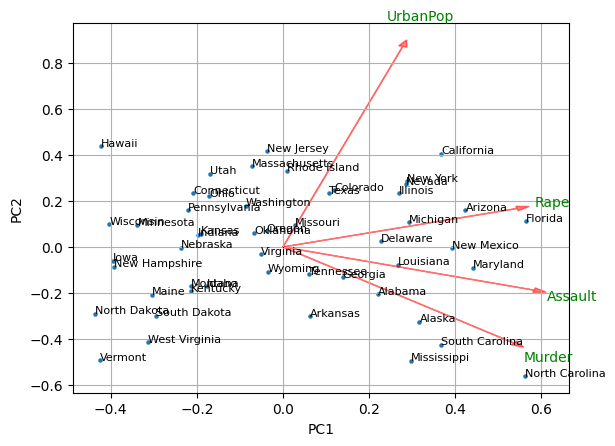

In [64]:
# Plot biplot
biplot(X_trans[:,0:2],np.transpose(pca.components_[0:2, :]),list(labels),list(arrests))
plt.show()

#### 6. Select the number of principal components to use in further analyses. Justify your choice.

In [65]:
# Explained variance
explained_var = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

variance_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(explained_var))],
    'Explained Variance': explained_var,
    'Cumulative Variance': cum_var
})

print(variance_df)

  Principal Component  Explained Variance  Cumulative Variance
0                 PC1            0.620060             0.620060
1                 PC2            0.247441             0.867502


The above implies that reducing the data from 4 dimensions to 2 dimensions loses only about 13% of the total information.
Therefore, using PC1 and PC2 is usually sufficient for visualization and further analysis.

The first principal component captures the majority of the variation in the dataset, while the second component captures a substantial additional proportion. Together, PC1 and PC2 explain approximately 87% of the total variance, indicating that two principal components adequately summarize the USArrests dataset and can be used for subsequent analyses with minimal loss of information.

#### 7. Apply two clustering techniques and an analysis of the clusters they generate. Comment on similarities between data points within each cluster.


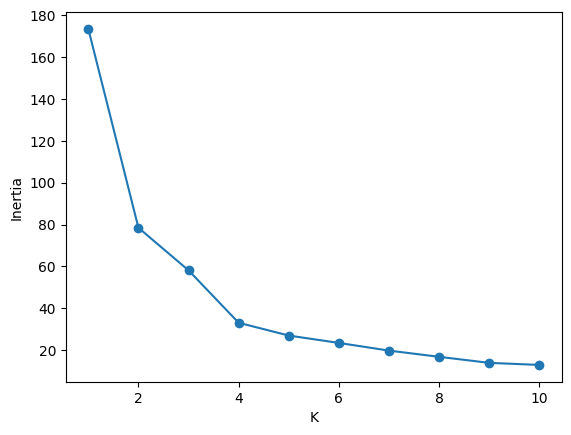

In [66]:
def eval_Kmeans(x, k, r):
    """
    Evaluate the KMeans clustering for a given number of clusters (k) and random seed (r),
    returning the inertia (sum of squared distances of samples to their closest center).

    Parameters:
    - x: Data to be clustered
    - k: Number of clusters
    - r: Random state for reproducibility

    Returns
    - inertia: Sum of squared distances within clusters.

    """
    kmeans = KMeans(n_clusters=k, random_state=r, max_iter=500)
    kmeans.fit(x)
    return kmeans.inertia_

def elbow_Kmeans(x, max_k=10, r=42):
    """"
    Plots the inertia (within-cluster variance) against the number of clusters to help determine
    the optimal number of clusters (the 'elbow point).

    Parameters:
    - x: Data to be clustered
    - max_k: Maximum number of clusters to evaluate (default is 10)
    - r: random state for reproducibility (default is 123).
    Args:

    """

    within_cluster_vars = [eval_Kmeans(x, k, r) for k in range(1,max_k+1)]
    plt.plot(range(1,11), within_cluster_vars, marker='o')
    plt.xlabel('K')
    plt.ylabel('Inertia')
    plt.show()

elbow_Kmeans(pca_df)   # Plot elbow curve using scaled dataset



As we can see the elbow or knee bend is 4

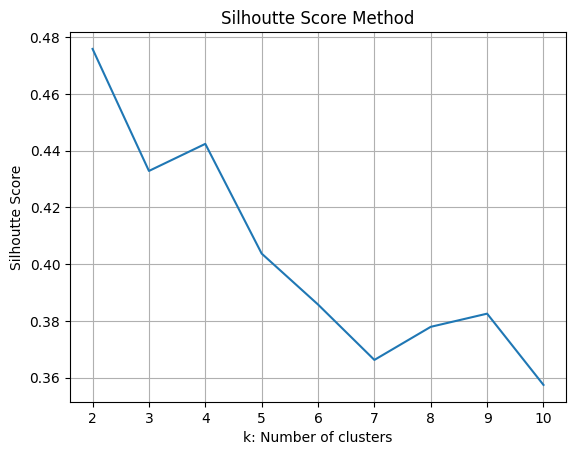

In [67]:
# Silhoutte score method
rseed = 42
kmax = 10
sil = []
plt.plot()
for k in range(2, kmax+1):
    kmeans = KMeans(n_clusters=k, random_state=rseed, max_iter=500)
    kmeans.fit(pca_df)
    labels = kmeans.labels_
    sil.append(silhouette_score(pca_df, labels, metric='euclidean'))

sns.lineplot(x=range(2, kmax+1), y=sil)
plt.title('Silhoutte Score Method')
plt.xlabel('k: Number of clusters')
plt.ylabel("Silhoutte Score")
plt.grid(visible=True)
plt.show()

### Fitting the K-Means model to the selected K value

In [68]:
# Fitting K-means model
# Remember to set the random_state to rseed
kmeans = KMeans(n_clusters=4, max_iter=1000, random_state=rseed)
kmeans.fit(pca_df)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",4
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",1000
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [69]:
# Count the number of observations in each cluster
pd.Series(kmeans.labels_).value_counts

<bound method IndexOpsMixin.value_counts of 0     2
1     2
2     1
3     2
4     1
5     1
6     3
7     3
8     1
9     2
10    3
11    0
12    1
13    3
14    0
15    3
16    0
17    2
18    0
19    1
20    3
21    1
22    3
23    2
24    1
25    0
26    3
27    1
28    0
29    3
30    1
31    1
32    2
33    0
34    3
35    3
36    3
37    3
38    3
39    2
40    0
41    2
42    1
43    3
44    0
45    3
46    3
47    0
48    0
49    3
dtype: int32>

Now we are going to check how the model is performaing using the silhoutte coefficient

In [70]:
# Check model performance with the silhoutte coefficient
metrics.silhouette_score(pca_df, kmeans.labels_)

0.4423620957291066

### Predictions

In [71]:
# Add the predicted cluster label column to the original dataframe
preds = kmeans.labels_
kmeans_df = pd.DataFrame(df)
kmeans_df['KMeans_clusters'] = preds
kmeans_df.head(10)

,Murder,Assault,UrbanPop,Rape,KMeans_clusters
City,,,,,
Alabama,13.200000,236,58,21.200000,2
Alaska,10.000000,263,48,44.500000,2
Arizona,8.100000,294,80,31.000000,1
Arkansas,8.800000,190,50,19.500000,2
California,9.000000,276,91,40.600000,1
Colorado,7.900000,204,78,38.700000,1
Connecticut,3.300000,110,77,11.100000,3
Delaware,5.900000,238,72,15.800000,3
Florida,15.400000,335,80,31.900000,1


### Visualisation of Clusters

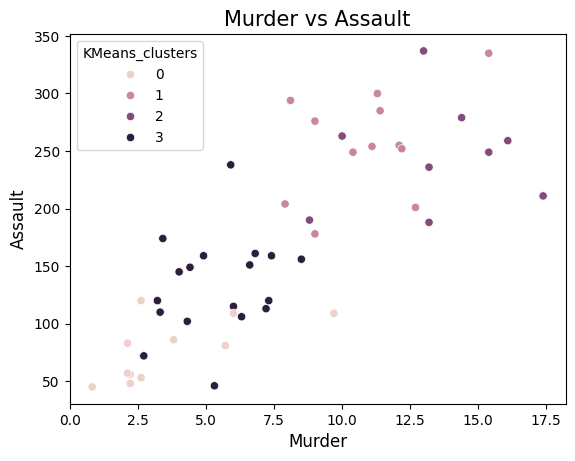

In [72]:
# Visualisation of clusters: child mortality vs gdpp

sns.scatterplot(x=kmeans_df['Murder'], y=kmeans_df['Assault'], hue='KMeans_clusters', data=kmeans_df)
plt.title('Murder vs Assault', fontsize=15)
plt.xlabel('Murder', fontsize=12)
plt.ylabel('Assault', fontsize=12)
plt.show()

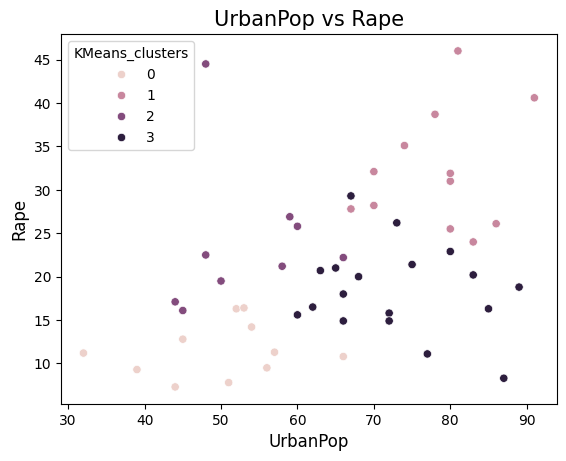

In [73]:
# Visualisation of clusters: child mortality vs gdpp

sns.scatterplot(x=kmeans_df['UrbanPop'], y=kmeans_df['Rape'], hue='KMeans_clusters', data=kmeans_df)
plt.title('UrbanPop vs Rape', fontsize=15)
plt.xlabel('UrbanPop', fontsize=12)
plt.ylabel('Rape', fontsize=12)
plt.show()

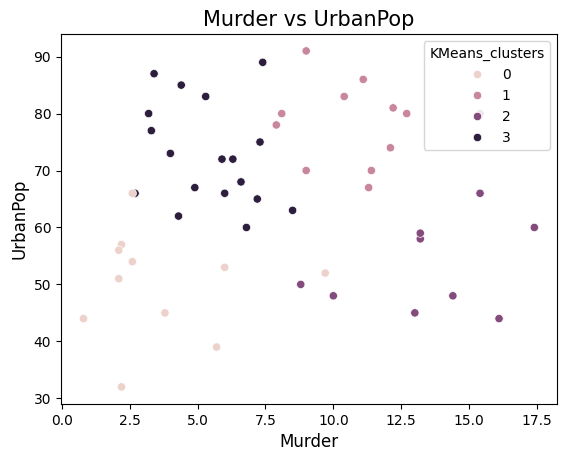

In [74]:
sns.scatterplot(x=kmeans_df['Murder'], y=kmeans_df['UrbanPop'], hue='KMeans_clusters', data=kmeans_df)
plt.title('Murder vs UrbanPop', fontsize=15)
plt.xlabel('Murder', fontsize=12)
plt.ylabel('UrbanPop', fontsize=12)
plt.show()

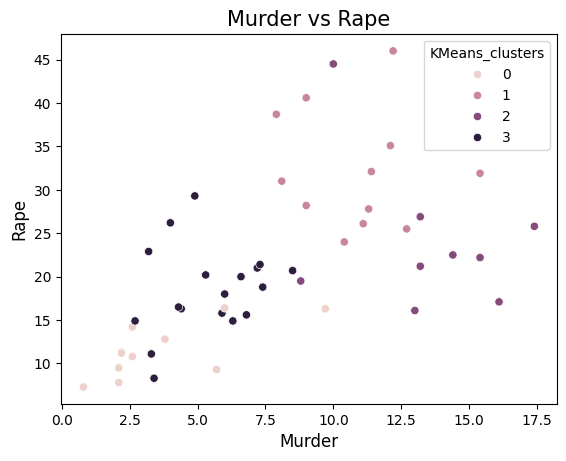

In [75]:
sns.scatterplot(x=kmeans_df['Murder'], y=kmeans_df['Rape'], hue='KMeans_clusters', data=kmeans_df)
plt.title('Murder vs Rape', fontsize=15)
plt.xlabel('Murder', fontsize=12)
plt.ylabel('Rape', fontsize=12)
plt.show()

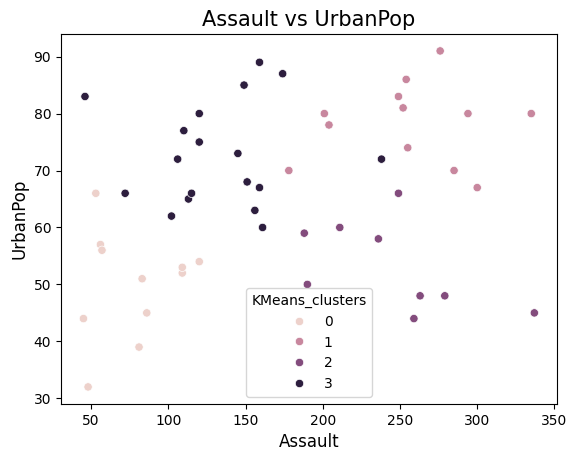

In [76]:
sns.scatterplot(x=kmeans_df['Assault'], y=kmeans_df['UrbanPop'], hue='KMeans_clusters', data=kmeans_df)
plt.title('Assault vs UrbanPop', fontsize=15)
plt.xlabel('Assault', fontsize=12)
plt.ylabel('UrbanPop', fontsize=12)
plt.show()

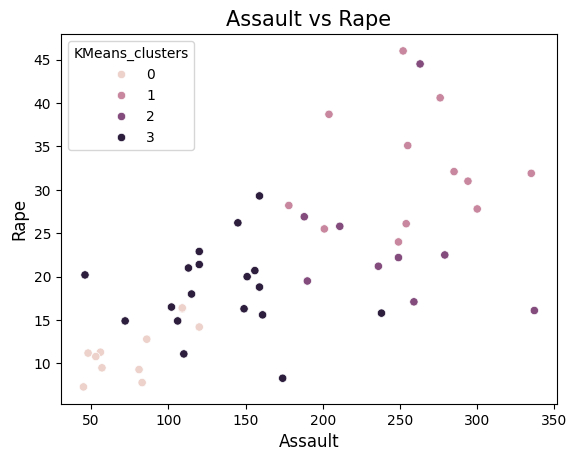

In [77]:
sns.scatterplot(x=kmeans_df['Assault'], y=kmeans_df['Rape'], hue='KMeans_clusters', data=kmeans_df)
plt.title('Assault vs Rape', fontsize=15)
plt.xlabel('Assault', fontsize=12)
plt.ylabel('Rape', fontsize=12)
plt.show()

### Dendrograms

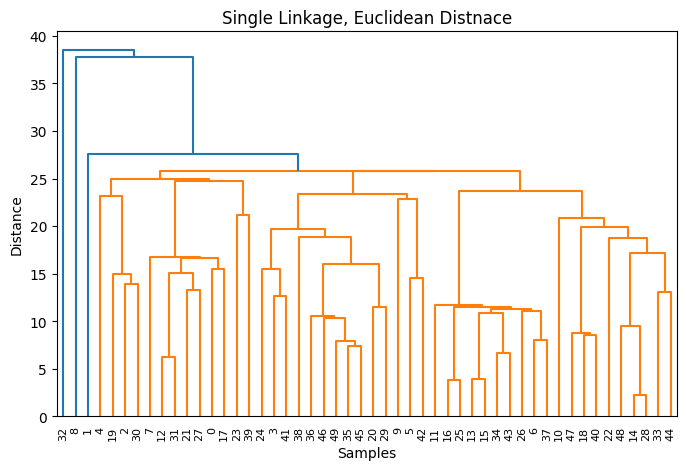

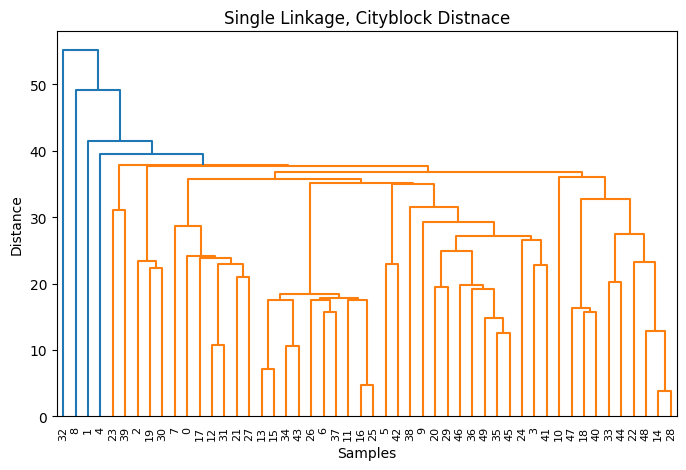

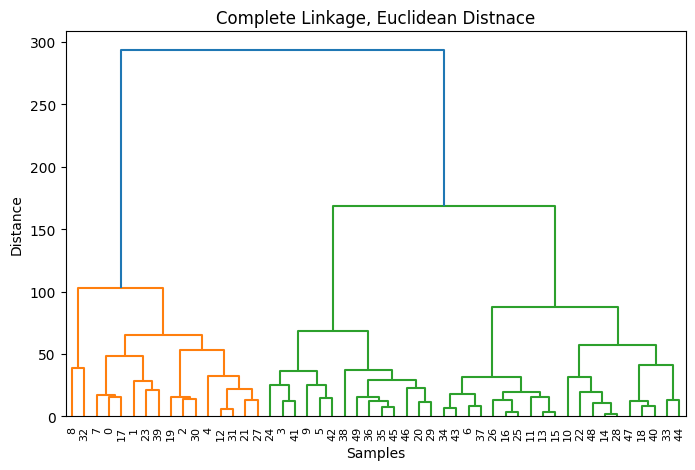

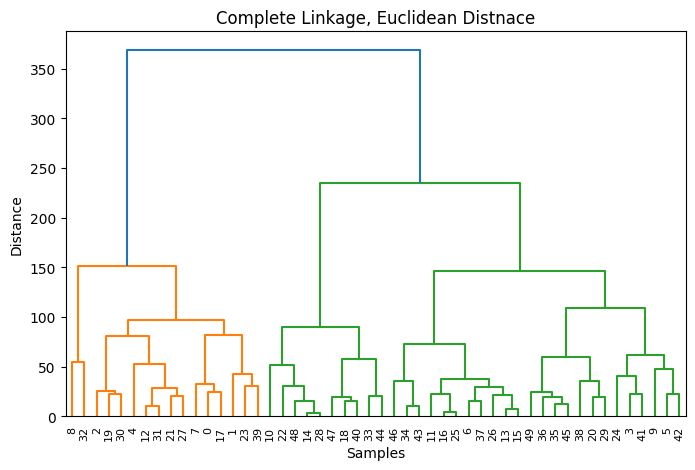

In [78]:
# Define a function to plot a dendrogram for a given linkage method and distance metrics
def plot_dendrogram(X, method, metric, title):
    plt.figure(figsize=(8,5))
    Z = linkage(X, method=method, metric=metric)
    dendrogram(Z)
    plt.title(title)
    plt.xlabel('Samples')
    plt.ylabel('Distance')
    plt.show()

# Plot the four dendrograms:
# Single linkage with Euclidean distance
plot_dendrogram(X, method = 'single', metric = 'euclidean', title = 'Single Linkage, Euclidean Distnace')

# Single linkage with Cityblock (Manhattan) distance
plot_dendrogram(X, method = 'single', metric = 'cityblock', title = 'Single Linkage, Cityblock Distnace')

# Complete Linkage with Euclidean distance
plot_dendrogram(X, method = 'complete', metric = 'euclidean', title = 'Complete Linkage, Euclidean Distnace')

# Complete linkage with Cityblock (Manhattan) distance
plot_dendrogram(X, method = 'complete', metric = 'cityblock', title = 'Complete Linkage, Euclidean Distnace')

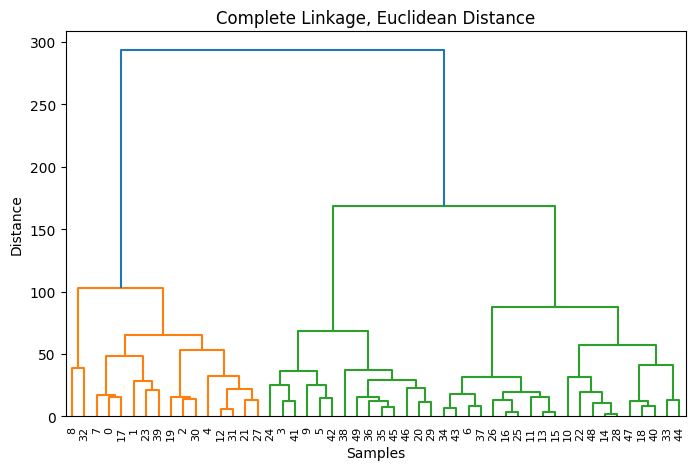

silhouette score:  0.531902
The clusters are well-defined, showing a high degree of separation.


In [79]:
# Plot the chosen dendrogram (Complete Linkage with Euclidean Distance)
plt.figure(figsize=(8, 5))
Z = linkage(X, method='complete', metric='euclidean')
dendrogram(Z)
plt.title('Complete Linkage, Euclidean Distance')
plt.xlabel('Samples')
plt.ylabel('Distance')
plt.show()

# Perform Agglomerative Hierarchical Clustering
# Assuming we select 3 clusters based on the dendrogram
agg_cluster = AgglomerativeClustering(n_clusters=3, linkage='complete', metric='euclidean')
labels = agg_cluster.fit_predict(X)

# calculate Silhoutte Score to evaluate clustering
silhouette_avg = silhouette_score(X, labels)
print(f"silhouette score: {silhouette_avg: 3f}")

# Comment on clustering confidence based on Silhouette Score
if silhouette_avg > 0.5:
    print("The clusters are well-defined, showing a high degree of separation.")
elif 0.2 < silhouette_avg <= 0.5:
    print("The clustering solution is acceptable but shows some overlap between clusters.")
else:
    print("The clusters are poorly defined, and the clustering solutions might need improvement")


The clusters which consists of Murder, UrbanPop, Assault and rape, the data points within the clusters are well-defined, this shows a high degree of separation 